In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("/content/diabetes.csv")

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

Shape: (768, 9)

Columns:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns] = df[columns].replace(0, np.nan)

print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


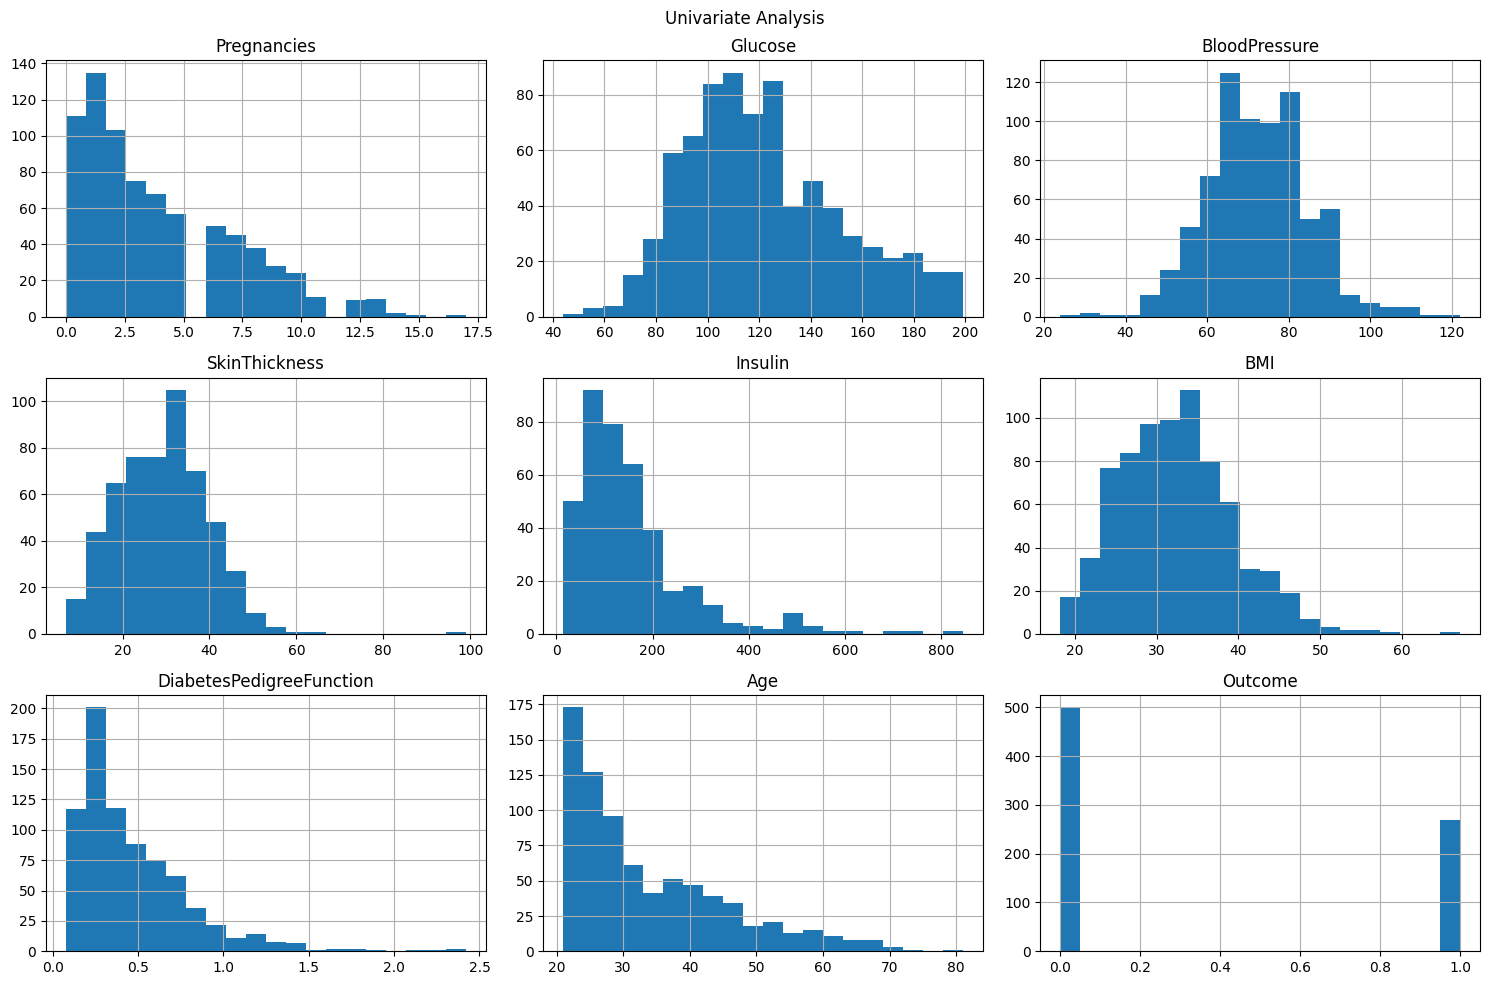

In [20]:
# Univariate
df.hist(figsize=(15, 10), bins=20)
plt.suptitle("Univariate Analysis")
plt.tight_layout()
plt.show()

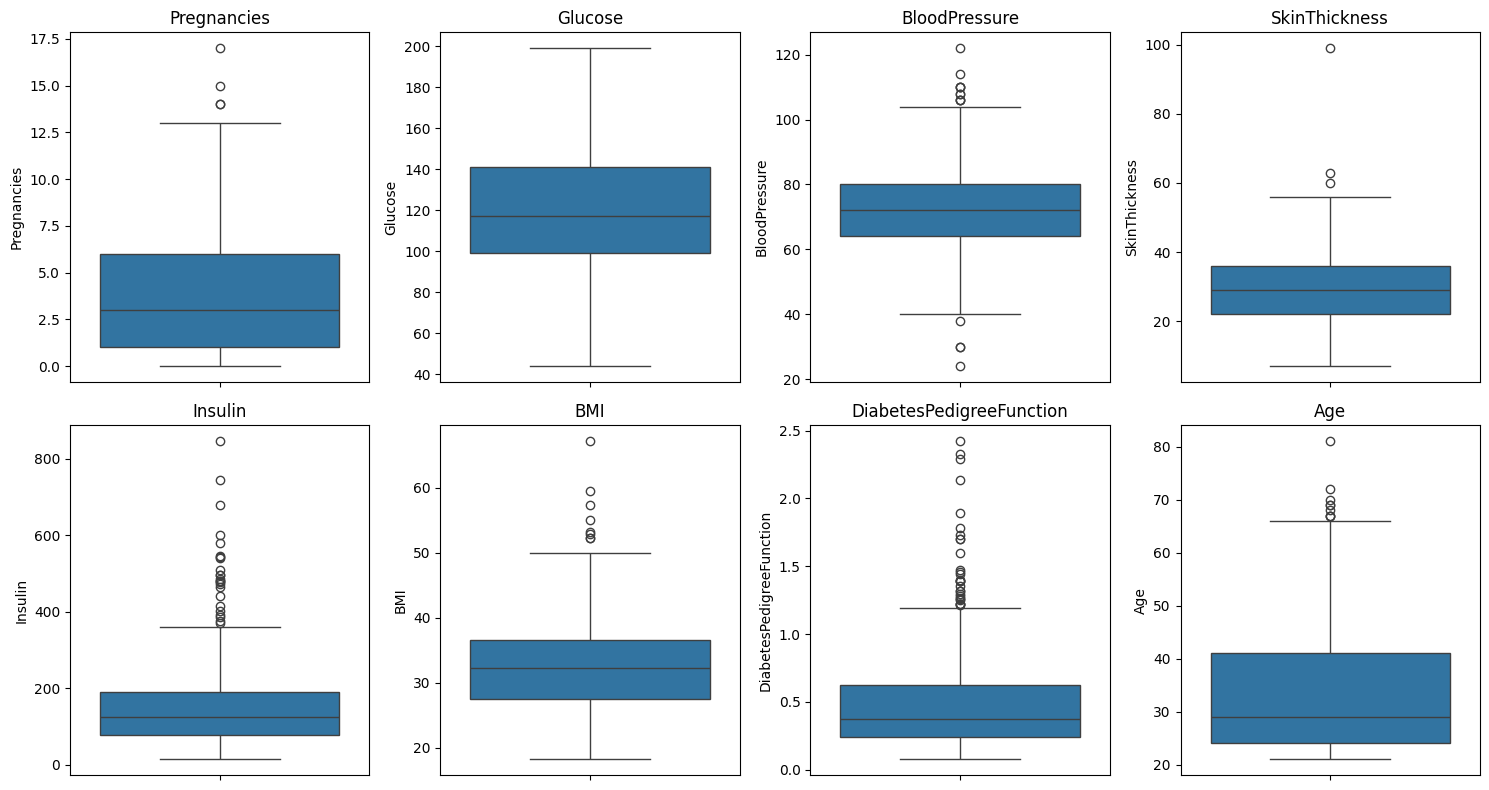

In [19]:

plt.figure(figsize=(15, 8))

for i, col in enumerate(df.columns[:-1]):
    plt.subplot(2, 4, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

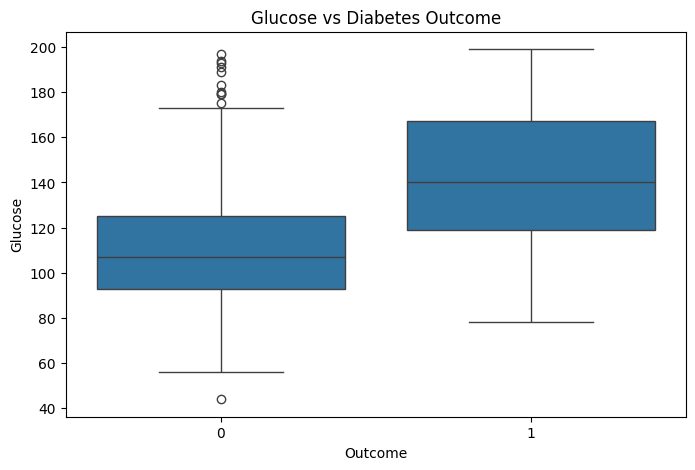

In [16]:
# Bivariate
plt.figure(figsize=(8, 5))

sns.boxplot(x='Outcome', y='Glucose', data=df)

plt.title("Glucose vs Diabetes Outcome")
plt.show()

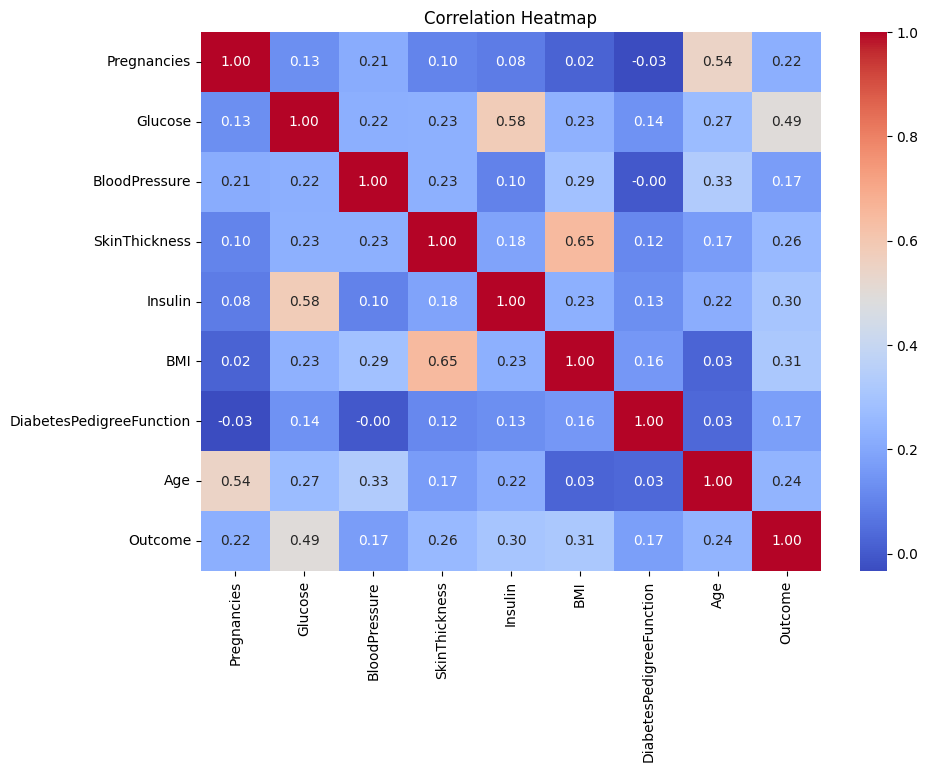

In [21]:
# Multivariate
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [22]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (768, 8)
Output Shape: (768,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [24]:
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

print("Missing Values After Imputation:")
print(X_train.isnull().sum())

Missing Values After Imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [25]:
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

print("Missing Values After Imputation:")
print(X_train.isnull().sum())

Missing Values After Imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [27]:
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model Training Completed")

Model Training Completed


In [28]:
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predicted Values:")
print(y_pred)

Predicted Values:
[1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0
 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 1 0 1 0 0 0 1 0 0 0 0 1 1 0 0 1 1 0 0 1 1 1 1 1 0 0 0 0 0 1 0 1 0 1 1 1
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1 1
 1 0 0 0 1 0]


In [29]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))


Accuracy: 0.7337662337662337


In [30]:
print("Precision:",
      precision_score(y_test, y_pred))


Precision: 0.6031746031746031


In [31]:
print("Recall:",
      recall_score(y_test, y_pred))

Recall: 0.7037037037037037


In [32]:
print("F1 Score:",
      f1_score(y_test, y_pred))


F1 Score: 0.6495726495726496


In [33]:
print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

ROC-AUC: 0.8125925925925926


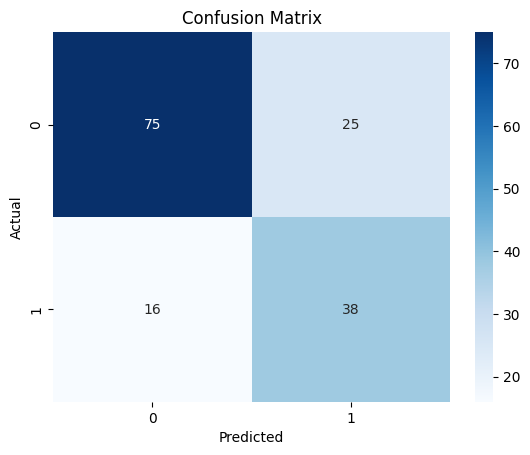

In [34]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

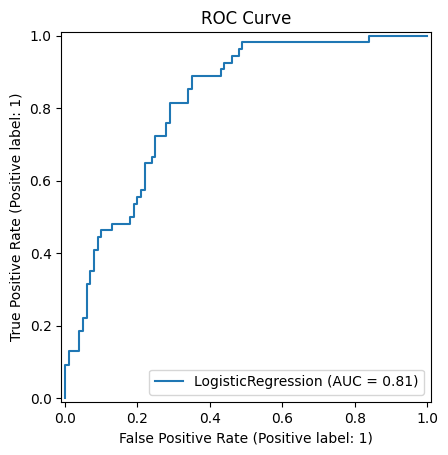

In [36]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)

plt.title("ROC Curve")
plt.show()

In [37]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



                    Feature  Coefficient
1                   Glucose     1.183483
5                       BMI     0.709592
0               Pregnancies     0.372902
6  DiabetesPedigreeFunction     0.287734
7                       Age     0.186434
3             SkinThickness     0.013980
2             BloodPressure    -0.014612
4                   Insulin    -0.044609


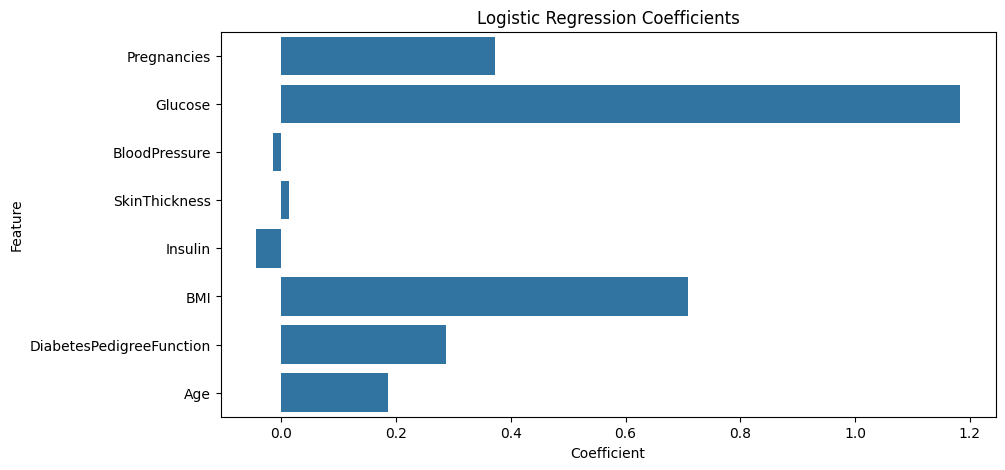

In [38]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print(coefficients.sort_values(
    by='Coefficient',
    ascending=False
))

plt.figure(figsize=(10, 5))

sns.barplot(
    x='Coefficient',
    y='Feature',
    data=coefficients
)

plt.title("Logistic Regression Coefficients")
plt.show()

In [40]:
print("""
CONCLUSION:

The Logistic Regression model was used to predict
diabetes using the Pima Indians Diabetes Dataset.

The dataset was cleaned using median imputation
and standardized using StandardScaler.

The model was evaluated using Accuracy, Precision,
Recall, F1-score and ROC-AUC.

Glucose and BMI showed strong positive model
coefficients in the project report.

This project is for educational purposes only
and is not suitable for medical diagnosis.
""")


CONCLUSION:

The Logistic Regression model was used to predict
diabetes using the Pima Indians Diabetes Dataset.

The dataset was cleaned using median imputation
and standardized using StandardScaler.

The model was evaluated using Accuracy, Precision,
Recall, F1-score and ROC-AUC.

Glucose and BMI showed strong positive model
coefficients in the project report.

This project is for educational purposes only
and is not suitable for medical diagnosis.

